# Week 2: Lasso, Ridge and Elastic Net Regression
Eric Benaroch, Module C Capstone

Research question from my proposal: does malicious behavior leave the same statistical pattern in different threat domains, or is every domain different?

The datasets are the same as Week 1: CICAndMal2017 (Android malware traffic), CICIDS2017 (network attacks) and WELFake (fake news). The targets are also the same: log of Flow Bytes/s for the network data and log of word count for WELFake.

In Week 1 I added polynomial and interaction terms, which gives many columns, and I dropped collinear features by hand using VIF. This week I let regularization deal with both problems:
1. Build a large feature set: all original features (including the collinear ones Week 1 dropped), their squares and cubes, and each feature times the malicious label.
2. Fit plain OLS as a baseline.
3. Fit lasso, ridge and elastic net, choosing lambda with cross-validation.
4. Compare how each method treats the collinear features.
5. Use lasso to find the few most important features in each domain and compare them across domains.
6. Show when regularization helps the most (small samples).

## 1. Setup

In [3]:
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.linear_model import Lasso, Ridge, ElasticNet
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.metrics import r2_score
import warnings
warnings.filterwarnings("ignore")      # hides convergence warnings for the smallest lambdas

import os
from pathlib import Path
DATA_DIR = Path(os.environ.get("CAPSTONE_DATA_DIR", "."))   # folder with the zips and the WELFake csv
FIG_DIR = Path("figures_week2"); FIG_DIR.mkdir(exist_ok=True)
SEED = 42
sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", "{:.3f}".format)

## 2. Load the data
The CIC files are read straight from the zip files, keeping only the columns used here. For CICAndMal2017 the folder name gives the category (Adware, Benign, Ransomware, Scareware, SMSmalware). For CICIDS2017 I use MachineLearningCSV, which has the same flows as GeneratedLabelledFlows but without IP addresses and timestamps.

In [5]:
COLS = {"Flow Duration": "dur", "Total Fwd Packets": "fwd_pkts", "Total Backward Packets": "bwd_pkts",
        "Fwd Packet Length Mean": "fwd_len", "Bwd Packet Length Mean": "bwd_len",
        "Flow IAT Mean": "iat", "Flow Bytes/s": "bytes_s", "Label": "label"}

def read_zip(zip_name):
    frames = []
    with zipfile.ZipFile(DATA_DIR / zip_name) as z:
        for name in z.namelist():
            if name.endswith(".csv"):
                df = pd.read_csv(z.open(name), skipinitialspace=True, encoding="latin1",
                                 usecols=lambda c: c.strip() in COLS)
                df.columns = df.columns.str.strip()
                frames.append(df)
    return pd.concat(frames, ignore_index=True).rename(columns=COLS)

mal_parts = []
for cat in ["Benign", "Adware", "Ransomware", "Scareware", "SMSmalware"]:
    df = read_zip(f"{cat}-CSVs.zip")
    df["category"] = cat
    mal_parts.append(df)
    print(cat, len(df))
mal_raw = pd.concat(mal_parts, ignore_index=True)

ids_raw = read_zip("MachineLearningCSV.zip")
print("CICIDS2017", len(ids_raw))
print(ids_raw["label"].value_counts())

Benign 1205515
Adware 424147
Ransomware 348943
Scareware 400841
SMSmalware 237133
CICIDS2017 2830743
label
BENIGN                          2273097
DoS Hulk                         231073
PortScan                         158930
DDoS                             128027
DoS GoldenEye                     10293
FTP-Patator                        7938
SSH-Patator                        5897
DoS slowloris                      5796
DoS Slowhttptest                   5499
Bot                                1966
Web Attack ï¿½ Brute Force         1507
Web Attack ï¿½ XSS                  652
Infiltration                         36
Web Attack ï¿½ Sql Injection         21
Heartbleed                           11
Name: count, dtype: int64


Ransomware 348943


Scareware 400841


SMSmalware 237133


CICIDS2017 2830743
label
BENIGN                          2273097
DoS Hulk                         231073
PortScan                         158930
DDoS                             128027
DoS GoldenEye                     10293
FTP-Patator                        7938
SSH-Patator                        5897
DoS slowloris                      5796
DoS Slowhttptest                   5499
Bot                                1966
Web Attack ï¿½ Brute Force         1507
Web Attack ï¿½ XSS                  652
Infiltration                         36
Web Attack ï¿½ Sql Injection         21
Heartbleed                           11
Name: count, dtype: int64


In [6]:
wel_raw = pd.read_csv(next(DATA_DIR.glob("WELFake*.csv")))      # finds WELFake_Dataset.csv
print(wel_raw.shape)
print(wel_raw["label"].value_counts())

# Which label is fake? Real news in WELFake is mostly Reuters wire copy.
print(wel_raw.groupby("label")["text"].apply(lambda s: s.str.contains("(Reuters)", regex=False).mean()))

(72134, 4)
label
1    37106
0    35028
Name: count, dtype: int64
label
0   0.607
1   0.000
Name: text, dtype: float64


The dataset card says label 1 means real, but in this file label 0 has the Reuters articles (about 61%) and label 1 has almost none. So label 1 is treated as fake (malicious = 1).

## 3. Clean and prepare
Network data: remove infinite and missing values, negative values, zero-length flows and duplicates, as in Module B. All flow features are very skewed (a few huge flows), so I take log1p of every feature and the target. I take a random sample so the models run quickly: 60,000 flows per CICAndMal2017 category, and 150,000 benign plus 150,000 attack flows for CICIDS2017.

WELFake: drop empty articles and duplicates, then make simple numeric features from the title and text.

In [9]:
def clean_flows(df):
    num = list(COLS.values())[:-1]
    df = df.copy()
    df[num] = df[num].apply(pd.to_numeric, errors="coerce")
    df = df.replace([np.inf, -np.inf], np.nan).dropna()
    df = df[(df[num] >= 0).all(axis=1) & (df["dur"] > 0)].drop_duplicates()
    for c in num:
        df[c] = np.log1p(df[c])
    return df.rename(columns={"bytes_s": "y"})

mal = clean_flows(mal_raw)
mal["malicious"] = (mal["category"] != "Benign").astype(int)
mal = mal.groupby("category").sample(60000, random_state=SEED)

def attack_group(label):
    label = label.upper()
    if label == "BENIGN": return "Benign"
    if "DOS" in label: return "DoS/DDoS"
    if "PATATOR" in label: return "BruteForce"
    if "WEB ATTACK" in label: return "WebAttack"
    if "PORTSCAN" in label: return "PortScan"
    return "Other"

ids = clean_flows(ids_raw)
ids["category"] = ids["label"].map(attack_group)
ids["malicious"] = (ids["category"] != "Benign").astype(int)
ids = ids.groupby("malicious").sample(150000, random_state=SEED)

print(mal["category"].value_counts(), "\n")
print(ids["category"].value_counts())

category
Adware        60000
Benign        60000
Ransomware    60000
SMSmalware    60000
Scareware     60000
Name: count, dtype: int64 

category
Benign        150000
DoS/DDoS      144190
BruteForce      3453
WebAttack        979
PortScan         762
Other            616
Name: count, dtype: int64


In [10]:
wel = wel_raw.dropna(subset=["text"]).fillna({"title": ""}).drop_duplicates(subset=["title", "text"])
wel = wel[wel["text"].str.split().str.len() > 0].copy()
wel["malicious"] = wel["label"]                                   # 1 = fake
wel["y"] = np.log1p(wel["text"].str.split().str.len())            # target: log word count
wel["title_words"] = np.log1p(wel["title"].str.split().str.len())
wel["title_chars"] = np.log1p(wel["title"].str.len())
wel["title_caps"] = wel["title"].str.count(r"[A-Z]") / wel["title"].str.len().clip(lower=1)   # share of capital letters
wel["exclaim"] = np.log1p(wel["title"].str.count("!") + wel["text"].str.count("!"))
wel["avg_word_len"] = wel["text"].str.len() / wel["text"].str.split().str.len()
wel["avg_word_len"] = wel["avg_word_len"].clip(upper=wel["avg_word_len"].quantile(0.99))
print(len(wel), "articles, fake share =", round(wel["malicious"].mean(), 2))

63110 articles, fake share = 0.45


In [11]:
NET_FEATS = ["dur", "fwd_pkts", "bwd_pkts", "fwd_len", "bwd_len", "iat"]
WEL_FEATS = ["title_words", "title_chars", "title_caps", "exclaim", "avg_word_len"]
DATA = {"CICAndMal2017": (mal, NET_FEATS), "CICIDS2017": (ids, NET_FEATS), "WELFake": (wel, WEL_FEATS)}

## 4. Build the feature set
Lesson-style columns, as in Week 1:
- the original features, centered on the training mean
- their squares and cubes (added with pd.concat)
- the malicious label and each feature times malicious (interaction terms)

This gives 25 columns for the network data and 21 for WELFake. The collinear features Week 1 removed (flow duration, backward packets, title characters) are kept on purpose, to see how lasso and ridge deal with them.

Lasso and ridge punish large coefficients, so every column must be on the same scale first. Otherwise a feature measured in big units would be punished less. I use StandardScaler, fit on the training set only.

In [13]:
def add_powers(df_X, degree):
    cols = list(df_X.columns)
    parts = [df_X]
    for d in range(2, degree + 1):
        parts.append((df_X ** d).rename(columns={f"{var}": f"{var}{d}" for var in cols}))
    return pd.concat(parts, axis=1)

def build_X(df, feats, means):
    X = add_powers(df[feats] - means, 3)
    X["malicious"] = df["malicious"]
    for f in feats:
        X[f + "_x_mal"] = (df[f] - means[f]) * df["malicious"]
    return X

SETS = {}
for name, (df, feats) in DATA.items():
    train, test = train_test_split(df, test_size=0.2, random_state=SEED, stratify=df["malicious"])
    means = train[feats].mean()
    X_train, X_test = build_X(train, feats, means), build_X(test, feats, means)
    scaler = StandardScaler().fit(X_train)
    X_train = pd.DataFrame(scaler.transform(X_train), columns=X_train.columns)
    X_test = pd.DataFrame(scaler.transform(X_test), columns=X_test.columns)
    SETS[name] = (X_train, X_test, train["y"].values, test["y"].values)
    print(f"{name}: {X_train.shape[1]} columns, {len(X_train)} train rows, {len(X_test)} test rows")

print(list(SETS["CICIDS2017"][0].columns))

CICAndMal2017: 25 columns, 240000 train rows, 60000 test rows
CICIDS2017: 25 columns, 240000 train rows, 60000 test rows
WELFake: 21 columns, 50488 train rows, 12622 test rows
['dur', 'fwd_pkts', 'bwd_pkts', 'fwd_len', 'bwd_len', 'iat', 'dur2', 'fwd_pkts2', 'bwd_pkts2', 'fwd_len2', 'bwd_len2', 'iat2', 'dur3', 'fwd_pkts3', 'bwd_pkts3', 'fwd_len3', 'bwd_len3', 'iat3', 'malicious', 'dur_x_mal', 'fwd_pkts_x_mal', 'bwd_pkts_x_mal', 'fwd_len_x_mal', 'bwd_len_x_mal', 'iat_x_mal']


## 5. Baseline: plain OLS on all columns
No regularization. The VIFs show how collinear this feature set is.

In [15]:
results = []      # (dataset, model, lambda, nonzero coefficients, test R2)
COEFS = {}        # coefficients of each model, for comparison later

for name, (X_train, X_test, y_train, y_test) in SETS.items():
    ols = sm.OLS(y_train, sm.add_constant(X_train)).fit()
    test_r2 = r2_score(y_test, ols.predict(sm.add_constant(X_test)))
    COEFS[(name, "OLS")] = ols.params.drop("const")
    results.append((name, "OLS", 0, X_train.shape[1], test_r2))
    sample = sm.add_constant(X_train.sample(20000, random_state=SEED))
    vifs = pd.Series([variance_inflation_factor(sample.values, i) for i in range(1, sample.shape[1])], index=X_train.columns)
    print(f"{name}: test R2 = {test_r2:.3f}, columns with VIF > 5: {(vifs > 5).sum()} of {len(vifs)}, "
          f"largest VIF = {vifs.max():,.0f}, largest |coef| = {ols.params.drop('const').abs().max():.2f}")

CICAndMal2017: test R2 = 0.913, columns with VIF > 5: 24 of 25, largest VIF = 1,305, largest |coef| = 6.03
CICIDS2017: test R2 = 0.948, columns with VIF > 5: 23 of 25, largest VIF = 1,239, largest |coef| = 2.71
WELFake: test R2 = 0.250, columns with VIF > 5: 16 of 21, largest VIF = 420, largest |coef| = 0.52


WELFake: test R2 = 0.250, columns with VIF > 5: 16 of 21, largest VIF = 420, largest |coef| = 0.52


Plain OLS fits well (test R2 of 0.91, 0.95 and 0.25), but almost every column has a VIF over 5, and the largest is over 1,000. The coefficients are unstable. In CICAndMal2017, duration gets +5.2 and inter-arrival time gets -6.0. These two large opposite coefficients mostly cancel each other out, which is the lesson's example of Y = 10 X1 - 8 X2 explaining the same data as a simpler model.

## 6. Choosing lambda
The lesson says to try lambda on a log scale (100, 10, 1, 0.1, 0.01, ...) and pick it with cross-validation. Note on names: sklearn calls lambda "alpha", and calls the lasso/ridge mix (the lesson's alpha) "l1_ratio".

For each model I run a grid search with 5-fold cross-validation on a 50,000 row sample of the training set. I then refit the best lambda on the full training set and score it on the test set.

In [18]:
LAMBDAS = np.logspace(-4, 3, 15)          # 0.0001 up to 1000
CV_CURVES = {}
BEST = {}

def tune(model, grid, name):
    X_train, X_test, y_train, y_test = SETS[name]
    idx = np.random.RandomState(SEED).choice(len(X_train), min(50000, len(X_train)), replace=False)
    search = GridSearchCV(model, grid, cv=5, scoring="r2").fit(X_train.iloc[idx], y_train[idx])
    best = search.best_estimator_.fit(X_train, y_train)
    return search, best, r2_score(y_test, best.predict(X_test))

for name in SETS:
    for label, model in [("Lasso", Lasso(max_iter=5000)), ("Ridge", Ridge())]:
        search, best, test_r2 = tune(model, {"alpha": LAMBDAS}, name)
        CV_CURVES[(name, label)] = search.cv_results_["mean_test_score"]
        COEFS[(name, label)] = pd.Series(best.coef_, index=SETS[name][0].columns)
        nonzero = int((np.abs(best.coef_) > 1e-6).sum())
        results.append((name, label, best.alpha, nonzero, test_r2))
        BEST[(name, label)] = best
        print(f"{name} {label}: best lambda = {best.alpha:.4g}, nonzero coefficients = {nonzero}, test R2 = {test_r2:.3f}")

CICAndMal2017 Lasso: best lambda = 0.0001, nonzero coefficients = 25, test R2 = 0.913
CICAndMal2017 Ridge: best lambda = 0.0001, nonzero coefficients = 25, test R2 = 0.913
CICIDS2017 Lasso: best lambda = 0.003162, nonzero coefficients = 22, test R2 = 0.948
CICIDS2017 Ridge: best lambda = 100, nonzero coefficients = 25, test R2 = 0.948
WELFake Lasso: best lambda = 0.0001, nonzero coefficients = 21, test R2 = 0.250
WELFake Ridge: best lambda = 10, nonzero coefficients = 21, test R2 = 0.250


CICIDS2017 Lasso: best lambda = 0.003162, nonzero coefficients = 22, test R2 = 0.948


CICIDS2017 Ridge: best lambda = 100, nonzero coefficients = 25, test R2 = 0.948


WELFake Lasso: best lambda = 0.0001, nonzero coefficients = 21, test R2 = 0.250


WELFake Ridge: best lambda = 10, nonzero coefficients = 21, test R2 = 0.250


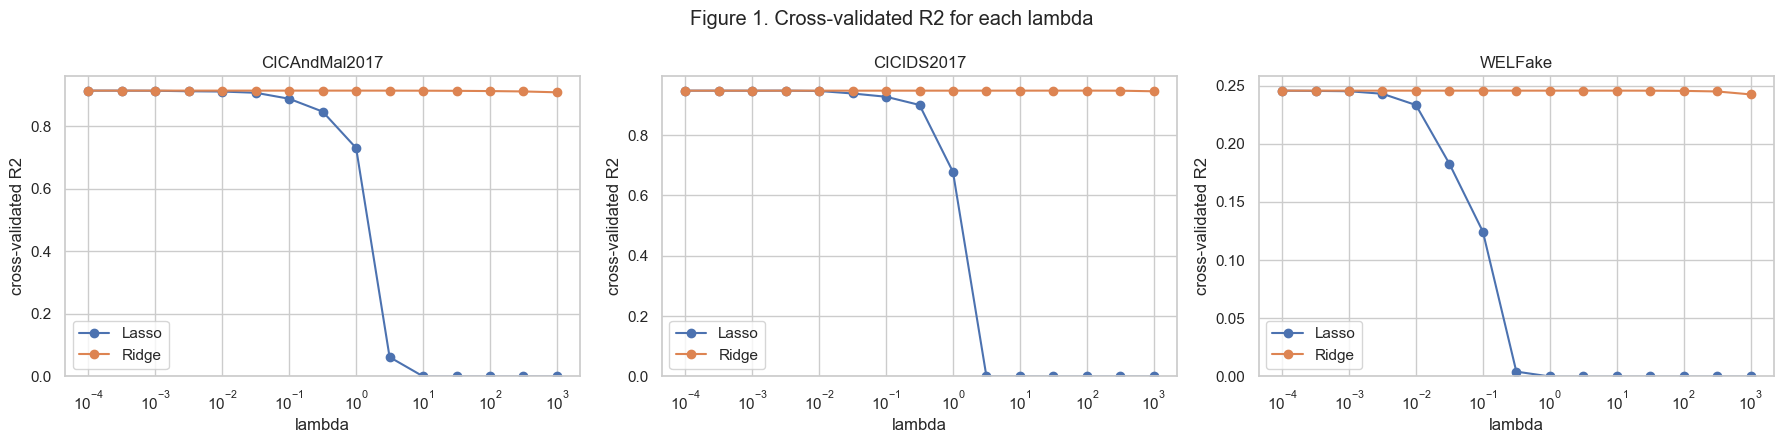

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
for ax, name in zip(axes, SETS):
    for label in ["Lasso", "Ridge"]:
        ax.plot(LAMBDAS, CV_CURVES[(name, label)], "o-", label=label)
    ax.set_xscale("log"); ax.set_xlabel("lambda"); ax.set_ylabel("cross-validated R2"); ax.set_title(name); ax.legend()
    ax.set_ylim(max(0, min(CV_CURVES[(name, "Lasso")].min(), CV_CURVES[(name, "Ridge")].min()) - 0.02), None)
fig.suptitle("Figure 1. Cross-validated R2 for each lambda")
plt.tight_layout(); plt.savefig(FIG_DIR / "fig1_lambda_cv.png", dpi=150); plt.show()

What the curves show:
- Lasso keeps the same R2 up to a lambda of about 0.01, then drops quickly as it removes more and more columns. By lambda 3 to 10 every coefficient is zero and R2 is 0.
- Ridge stays almost flat across the whole range. With 240,000 rows the error term is very large compared with the penalty, so even lambda 1000 barely changes the coefficients.
- Cross-validation picked very small lambdas (0.0001 to 0.003 for lasso). This means that with this much data there is little overfitting to fix, so the best model is close to plain OLS. Test R2 is the same for OLS, lasso and ridge in every dataset.

## 7. Lasso path: how coefficients go to zero
The lesson explains that lasso pushes a coefficient all the way to zero when keeping it does not improve the fit by more than lambda. Here I refit lasso for a range of lambdas and plot every coefficient. As lambda grows, coefficients drop to zero one by one. The ones that survive longest are the most important.

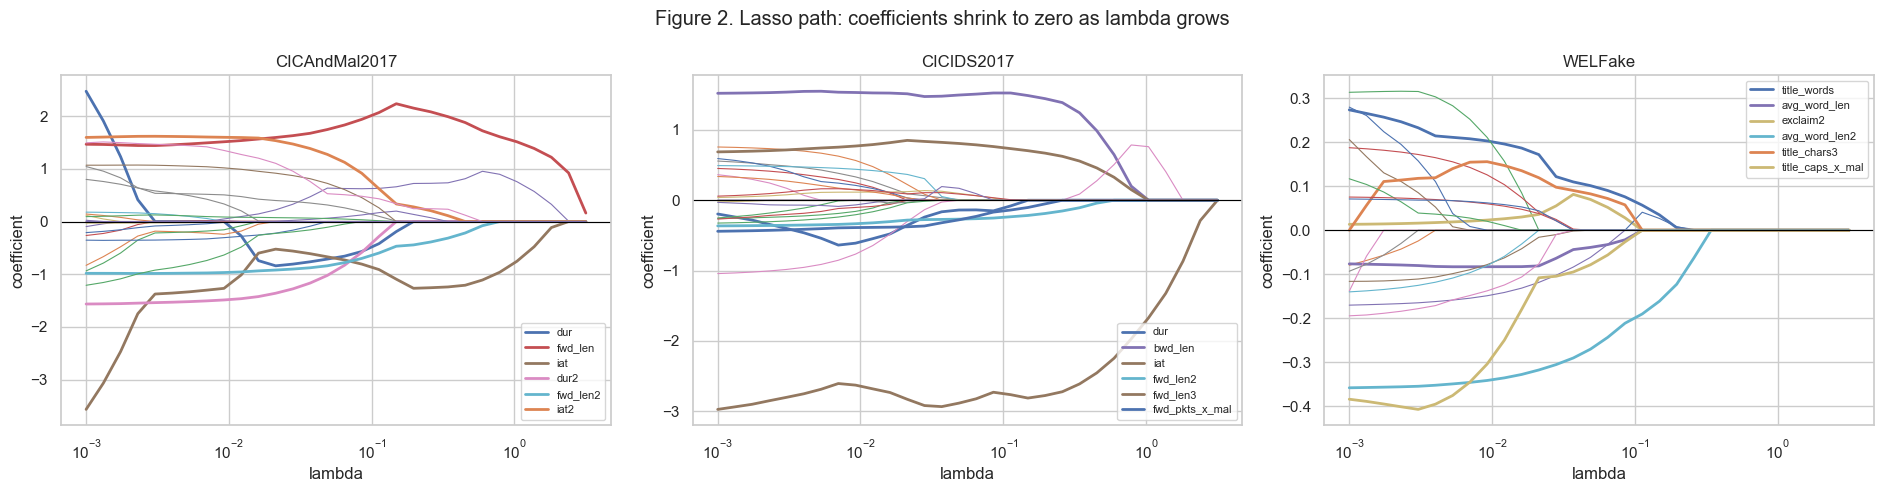

CICAndMal2017 nonzero coefficients at each lambda: [23 22 21 21 18 18 18 19 19 19 19 16 14 14 13 13 12 12  9  7  7  6  5  4
  3  3  3  3  2  1]
CICIDS2017 nonzero coefficients at each lambda: [22 22 22 22 21 21 20 20 19 20 19 16 14 12 10  9  9  7  5  5  4  5  5  4
  4  2  2  1  1  0]
WELFake nonzero coefficients at each lambda: [19 20 19 19 18 17 17 16 15 15 14 12 12 10  7  7  6  3  3  3  1  0  0  0
  0  0  0  0  0  0]


In [22]:
PATH_LAMBDAS = np.logspace(-3, 0.5, 30)
PATHS = {}
for name, (X_train, X_test, y_train, y_test) in SETS.items():
    idx = np.random.RandomState(SEED).choice(len(X_train), min(50000, len(X_train)), replace=False)
    PATHS[name] = pd.DataFrame([Lasso(alpha=a, max_iter=5000).fit(X_train.iloc[idx], y_train[idx]).coef_ for a in PATH_LAMBDAS],
                               index=PATH_LAMBDAS, columns=X_train.columns)

fig, axes = plt.subplots(1, 3, figsize=(19, 5))
for ax, name in zip(axes, SETS):
    path = PATHS[name]
    top = path.iloc[len(path) // 2].abs().sort_values(ascending=False).index[:6]   # label the strongest ones
    for col in path.columns:
        ax.plot(path.index, path[col], lw=2 if col in top else 0.8, label=col if col in top else None)
    ax.set_xscale("log"); ax.axhline(0, color="black", lw=0.8)
    ax.set_xlabel("lambda"); ax.set_ylabel("coefficient"); ax.set_title(name); ax.legend(fontsize=8)
fig.suptitle("Figure 2. Lasso path: coefficients shrink to zero as lambda grows")
plt.tight_layout(); plt.savefig(FIG_DIR / "fig2_lasso_path.png", dpi=150); plt.show()

for name, path in PATHS.items():
    print(name, "nonzero coefficients at each lambda:", (path.abs() > 1e-6).sum(axis=1).values)

## 8. How lasso and ridge treat collinear features
The lesson says lasso handles multicollinearity by more or less dropping one of the related features, while ridge keeps all of them with smaller coefficients. The table shows the tuned models from section 6 plus a stronger lambda for each, so the difference is easier to see. Week 1 found these collinear groups:
- network data: flow duration is almost a combination of inter-arrival time and packet counts
- WELFake: title words and title characters

In [24]:
PAIRS = {"CICAndMal2017": ["dur", "iat", "fwd_pkts", "bwd_pkts"],
         "CICIDS2017": ["dur", "iat", "fwd_pkts", "bwd_pkts"],
         "WELFake": ["title_words", "title_chars"]}

for name, cols in PAIRS.items():
    X_train, X_test, y_train, y_test = SETS[name]
    table = pd.DataFrame({m: COEFS[(name, m)][cols] for m in ["OLS", "Lasso", "Ridge"]})
    # stronger penalties make the difference easier to see
    table["Lasso, lambda 0.1"] = pd.Series(Lasso(alpha=0.1, max_iter=5000).fit(X_train, y_train).coef_, index=X_train.columns)[cols]
    table["Ridge, lambda 10000"] = pd.Series(Ridge(alpha=10000).fit(X_train, y_train).coef_, index=X_train.columns)[cols]
    print(name); print(table.round(3), "\n")

CICAndMal2017
            OLS  Lasso  Ridge  Lasso, lambda 0.1  Ridge, lambda 10000
dur       5.227  4.590  5.227             -0.521               -0.541
iat      -6.030 -5.458 -6.030             -0.837               -0.769
fwd_pkts -1.665 -1.499 -1.665             -0.000               -0.086
bwd_pkts -1.575 -1.429 -1.575              0.000                0.013 

CICIDS2017
            OLS  Lasso  Ridge  Lasso, lambda 0.1  Ridge, lambda 10000
dur      -1.282 -0.513 -1.082             -0.130               -1.354
iat      -2.054 -2.727 -2.229             -2.719               -1.675
fwd_pkts  0.238  0.000  0.183             -0.000                0.133
bwd_pkts -0.130 -0.121 -0.144             -0.000                0.073 

WELFake
               OLS  Lasso  Ridge  Lasso, lambda 0.1  Ridge, lambda 10000
title_words  0.337  0.328  0.333              0.065                0.130
title_chars -0.176 -0.160 -0.168              0.000                0.030 



This matches the lesson:
- With a stronger penalty, lasso drops one side of each collinear group. At lambda 0.1 it sets forward packets and backward packets to zero in both network datasets and title characters to zero in WELFake, and keeps the related feature (inter-arrival time, title words). Even the tuned CICIDS2017 lasso already drops forward packets.
- Ridge keeps every feature but shrinks them. At lambda 10000 all coefficients are nonzero and much smaller.
- The large, opposite-sign OLS coefficients for duration and inter-arrival time in CICAndMal2017 (+5.2 and -6.0) shrink to about -0.5 and -0.8 under both penalties. Both now have the same sign and make physical sense: longer flows and longer gaps mean lower throughput.

## 9. Elastic net
Elastic net mixes the lasso and ridge penalties. I search over lambda and the mix (l1_ratio of 0.1, 0.5 and 0.9, where 1 would be pure lasso and 0 pure ridge).

In [ ]:
for name in SETS:
    search, best, test_r2 = tune(ElasticNet(max_iter=5000), {"alpha": LAMBDAS[:10], "l1_ratio": [0.1, 0.5, 0.9]}, name)
    COEFS[(name, "Elastic net")] = pd.Series(best.coef_, index=SETS[name][0].columns)
    nonzero = int((np.abs(best.coef_) > 1e-6).sum())
    results.append((name, "Elastic net", best.alpha, nonzero, test_r2))
    print(f"{name}: best lambda = {best.alpha:.4g}, l1_ratio = {best.l1_ratio}, nonzero = {nonzero}, test R2 = {test_r2:.3f}")

WELFake: best lambda = 0.0001, l1_ratio = 0.1, nonzero = 21, test R2 = 0.250


## 10. Comparing all four models

In [ ]:
summary = pd.DataFrame(results, columns=["dataset", "model", "lambda", "nonzero coefs", "test R2"])
summary

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(20, 7), sharey=False)
for ax, name in zip(axes, SETS):
    table = pd.DataFrame({m: COEFS[(name, m)] for m in ["OLS", "Lasso", "Elastic net", "Ridge"]})
    table = table.clip(-3, 3)          # keep the color scale readable; OLS has some very large values
    sns.heatmap(table, cmap="coolwarm", center=0, ax=ax, cbar=name == "WELFake", annot=False)
    ax.set_title(name)
fig.suptitle("Figure 3. Coefficients of every column under each model (clipped to -3..3; white = zero)")
plt.tight_layout(); plt.savefig(FIG_DIR / "fig3_coef_heatmap.png", dpi=150); plt.show()

All four models give the same test R2, so with this much data the choice of model does not change accuracy. What changes is the coefficients. OLS has the most extreme values (dark cells, especially the duration and interaction columns in CICIDS2017). Lasso and elastic net shrink or remove these. Ridge sits in between. Elastic net picked a mix close to lasso for CICIDS2017 (l1_ratio 0.5) and kept 23 of 25 columns, between lasso (22) and ridge (25), as the lesson describes.

## 11. When does regularization help? (small samples)
With hundreds of thousands of rows and only about 25 columns, overfitting is not a big risk, so OLS is hard to beat. The lesson's grocery example is different: 100 items and not many shoppers. To copy that situation, I train each model on only 200 rows and test on the full test set. This is repeated 20 times with different random samples, and the results are averaged. Lambda is chosen by 5-fold cross-validation inside each 200-row sample.

In [ ]:
small_rows = []
for name, (X_train, X_test, y_train, y_test) in SETS.items():
    for rep in range(20):
        idx = np.random.RandomState(rep).choice(len(X_train), 200, replace=False)
        Xs, ys = X_train.iloc[idx], y_train[idx]
        ols_small = sm.OLS(ys, sm.add_constant(Xs)).fit()
        small_rows.append((name, "OLS", r2_score(y_test, ols_small.predict(sm.add_constant(X_test)))))
        for label, model in [("Lasso", Lasso(max_iter=5000)), ("Ridge", Ridge())]:
            search = GridSearchCV(model, {"alpha": LAMBDAS}, cv=5, scoring="r2").fit(Xs, ys)
            small_rows.append((name, label, r2_score(y_test, search.predict(X_test))))

small = pd.DataFrame(small_rows, columns=["dataset", "model", "test R2"])
small_table = small.groupby(["dataset", "model"])["test R2"].median().unstack()
print("Median test R2 over 20 samples of 200 rows:")
display(small_table)

fig, ax = plt.subplots(figsize=(11, 4.5))
sns.boxplot(data=small.assign(**{"test R2": small["test R2"].clip(lower=-1)}), x="dataset", y="test R2", hue="model", ax=ax)
ax.set_title("Figure 4. Test R2 when training on only 200 rows (20 repeats, values below -1 shown at -1)")
plt.tight_layout(); plt.savefig(FIG_DIR / "fig4_small_sample.png", dpi=150); plt.show()

With only 200 training rows, regularization helps:
- CICAndMal2017: OLS 0.881, lasso 0.893, ridge 0.891
- CICIDS2017: OLS 0.910, lasso 0.928, ridge 0.927
- WELFake: OLS -0.456, lasso 0.082, ridge 0.098

WELFake shows the biggest effect. With 21 columns, a weak signal and only 200 rows, OLS overfits so badly that it does worse than predicting the average (negative R2). Lasso and ridge bring it back to a positive R2. This is the lesson's grocery situation: many features and not much data.

## 12. Most important features in each domain
To connect this to the research question, I use a strong lambda so that lasso keeps only about 5 columns in each dataset. These are the features each domain relies on most. If the same kinds of features survive in both network datasets, including the malicious interaction terms, that would point to a shared pattern.

In [ ]:
TOP = {}
for name, path in PATHS.items():
    nonzero = (path.abs() > 1e-6).sum(axis=1)
    lam = nonzero[nonzero >= 5].index.max()             # largest lambda that still keeps 5 or more columns
    kept = path.loc[lam][path.loc[lam].abs() > 1e-6].sort_values(key=abs, ascending=False)
    TOP[name] = kept
    print(f"{name} (lambda = {lam:.3f}):")
    print(kept.round(3).to_string(), "\n")

net = pd.DataFrame({n: TOP[n] for n in ["CICAndMal2017", "CICIDS2017"]})
print("Kept in both network datasets:", list(net.dropna().index))

Results:
- The two network datasets share 4 of their top 5 columns: inter-arrival time, backward packet length (and its cube) and forward packet length squared. Packet size and packet timing are the most important features in both domains, matching Week 1 and the Module B random forest.
- None of the feature times malicious columns survive in either network dataset. The difference between malicious and benign traffic is small compared with the basic size and timing relationship.
- WELFake keeps different kinds of features (word length, title length, exclamation marks), as expected for text. It is the only dataset where an interaction with the malicious label survives (title capitals times fake), matching the Week 1 finding that capital letters behave differently in fake news.
- For the research question, the two network domains share the same main drivers of throughput. Their malicious signatures (Week 1 interactions) were still different. In Module C, lasso can be used as a first filter to choose a small, shared feature set before the SHAP comparison.

## 13. Answers to the Think About It questions, using my data

Why does lasso drop some coefficients? The penalty is lambda times the absolute value, so making a coefficient smaller always saves the same amount. If the fit gets worse by less than that, the coefficient keeps shrinking until it hits zero. Here that happened to forward packets, backward packets and title characters, which add little once their collinear partners are in the model.

Why does ridge not drop coefficients? The penalty is the square, so the saving from shrinking a coefficient gets smaller as the coefficient gets close to zero. At some point keeping a small coefficient is worth it. Even at lambda 10000 ridge kept all 25 columns.

When would I prefer lasso? When I want a short list of the important features, like section 12, or to pick features for the SHAP comparison in Module C.

When would I prefer ridge? When I believe all the features matter and they are collinear, as in the packet count and duration group, and I want stable coefficients without throwing any feature away.

When would I prefer no regularization? When there are many more rows than columns, as in my full datasets (240,000 rows, 25 columns). Here OLS, lasso and ridge all had the same test R2, and the cross-validated lambda was close to zero.

## 14. Notes for the Milestone One write-up
| Rubric item | What I did |
|---|---|
| Avoiding overfitting | Lasso, ridge and elastic net penalties, 80/20 train/test split, 5-fold cross-validation for lambda, and the 200-row experiment in section 11 |
| Metrics | Test R2 and number of nonzero coefficients |
| Hyperparameter tuning | Lambda searched on a log scale from 0.0001 to 1000 with GridSearchCV; elastic net also searched l1_ratio 0.1, 0.5, 0.9 |
| How EDA helped | Week 1 VIF results told me which features were collinear, so I could check how lasso and ridge handled them |